frames used: 100
avg min/max: 0.0 360.0
RL min/max: -4.161856439044707e-43 1.1291515827178955
connected components found: 15
components successfully fit: 14
final spots after 1-vs-2 Gaussian fitting: 17
15-16: dx=-1.38, dy=19.87, d=19.92


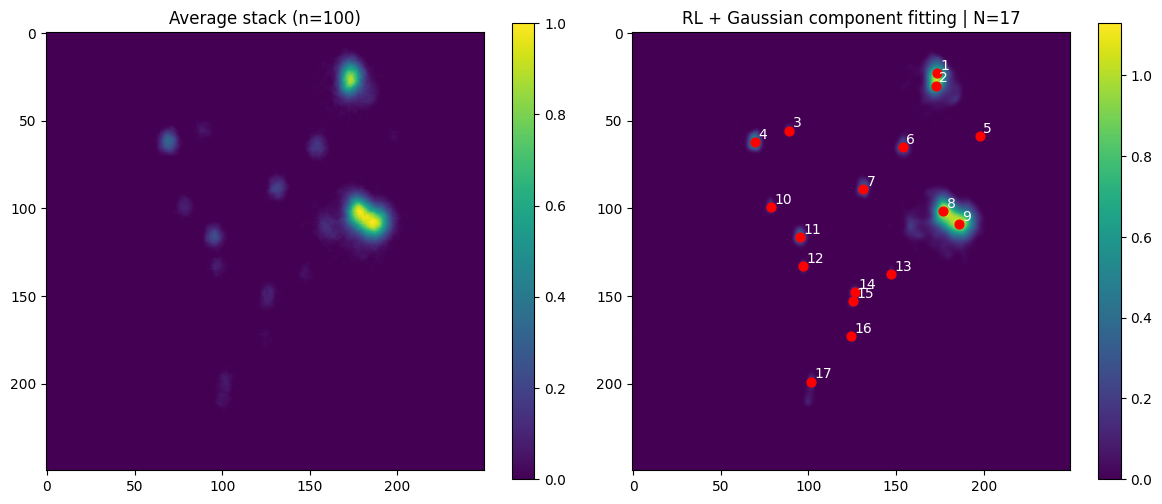

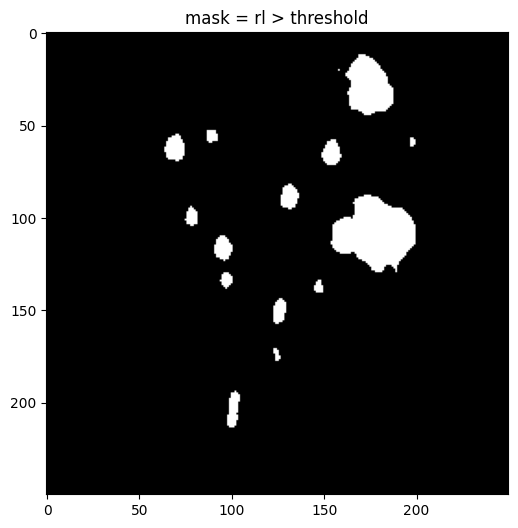

comp  1 | area= 607 | model=2 | bic1=-7742.92 | bic2=-9349.89 | sep=7.30
comp  3 | area=  36 | model=1 | bic1=-2334.75 | bic2=-2518.18 | sep=2.15
comp  4 | area= 123 | model=1 | bic1=-2915.65 | bic2=-3604.90 | sep=4.54
comp  5 | area=  13 | model=1 | bic1=-1666.03 | bic2=-1843.07 | sep=1.87
comp  6 | area= 109 | model=1 | bic1=-3303.58 | bic2=-3807.81 | sep=4.65
comp  7 | area= 103 | model=1 | bic1=-3067.54 | bic2=-3620.24 | sep=4.07
comp  8 | area=1265 | model=2 | bic1=-13177.45 | bic2=-17492.09 | sep=11.56
comp  9 | area=  53 | model=1 | bic1=-2488.88 | bic2=-3234.00 | sep=3.50
comp 10 | area= 100 | model=1 | bic1=-3084.02 | bic2=-3779.64 | sep=3.97
comp 11 | area=  42 | model=1 | bic1=-2455.39 | bic2=-2927.35 | sep=2.53
comp 12 | area=  27 | model=1 | bic1=-1934.24 | bic2=-2220.29 | sep=3.05
comp 13 | area=  77 | model=2 | bic1=-2519.78 | bic2=-3269.46 | sep=5.27
comp 14 | area=  18 | model=1 | bic1=-1877.53 | bic2=-2238.36 | sep=3.88
comp 15 | area=  97 | model=1 | bic1=-3207.38 | 

In [20]:
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import ndimage as ndi
from scipy.optimize import curve_fit
from skimage.restoration import richardson_lucy

# ---------------------------
# SETTINGS
# ---------------------------
#image_folder = "/Users/bananyamani/Desktop/PSI/50ms_cropped_clean"
image_folder = "/Users/bananyamani/Desktop/PSI/50ms_cropped_clean"
# stacking / RL
n_images = 100
rl_iters = 10
psf_sigma = 2.0
psf_size = 15

# detection / fitting
threshold = 0.02   # RL image is normalized, so threshold must be small, not 8
min_component_area = 3
max_component_area = 10000
roi_pad = 4

bic_improvement_needed = 25
min_two_spot_sep = 5

# ---------------------------
# LOAD + AVERAGE STACK
# ---------------------------
files = sorted(Path(image_folder).glob("clean_frame_*.tif"))[:n_images]
if len(files) == 0:
    raise RuntimeError("No files found matching clean_frame_*.tif")

stack = None
for f in files:
    frame = tiff.imread(f).astype(np.float32)
    if stack is None:
        stack = frame.copy()
    else:
        stack += frame

stack /= float(len(files))
avg = stack.astype(np.float32)

print("frames used:", len(files))
print("avg min/max:", float(avg.min()), float(avg.max()))

# ---------------------------
# BUILD GAUSSIAN PSF
# ---------------------------
ax = np.arange(-(psf_size // 2), psf_size // 2 + 1)
xx, yy = np.meshgrid(ax, ax)
psf = np.exp(-(xx**2 + yy**2) / (2 * psf_sigma**2))
psf /= psf.sum()

# ---------------------------
# NORMALIZE + RICHARDSON-LUCY
# ---------------------------
avg_norm = avg - avg.min()
avg_norm /= (avg_norm.max() + 1e-12)

rl = richardson_lucy(avg_norm, psf, num_iter=rl_iters, clip=False).astype(np.float32)

img = rl
img_min = float(img.min())
img_max = float(img.max())

print("RL min/max:", img_min, img_max)

# ---------------------------
# THRESHOLD + CONNECTED COMPONENTS
# ---------------------------
mask = img > threshold
cc_labels, n_cc = ndi.label(mask)

print("connected components found:", n_cc)

areas = np.bincount(cc_labels.ravel())

# ---------------------------
# GAUSSIAN FIT HELPERS
# ---------------------------
def gauss2d_1(coords, A1, x01, y01, s1, B):
    x, y = coords
    g1 = A1 * np.exp(-((x - x01)**2 + (y - y01)**2) / (2 * s1**2))
    return (g1 + B).ravel()

def gauss2d_2(coords, A1, x01, y01, s1, A2, x02, y02, s2, B):
    x, y = coords
    g1 = A1 * np.exp(-((x - x01)**2 + (y - y01)**2) / (2 * s1**2))
    g2 = A2 * np.exp(-((x - x02)**2 + (y - y02)**2) / (2 * s2**2))
    return (g1 + g2 + B).ravel()

def bic_from_rss(rss, n, k):
    rss = max(rss, 1e-12)
    return n * np.log(rss / n) + k * np.log(n)

def fit_component_roi(img, x1, x2, y1, y2):
    roi = img[y1:y2, x1:x2].astype(float)

    yy, xx = np.indices(roi.shape)
    xdata = xx.ravel()
    ydata = yy.ravel()
    zdata = roi.ravel()

    B0 = float(np.median(roi))
    A0 = float(roi.max() - B0)

    iy, ix = np.unravel_index(np.argmax(roi), roi.shape)

    p0_1 = [A0, ix, iy, 2.5, B0]
    bounds_1 = (
        [0, 0, 0, 0.5, 0],
        [1e6, roi.shape[1], roi.shape[0], 10, 1e6]
    )

    popt1, _ = curve_fit(
        gauss2d_1, (xdata, ydata), zdata,
        p0=p0_1, bounds=bounds_1, maxfev=20000
    )
    fit1 = gauss2d_1((xx, yy), *popt1).reshape(roi.shape)
    rss1 = float(np.sum((roi - fit1)**2))
    bic1 = bic_from_rss(rss1, roi.size, 5)

    p0_2 = [0.7*A0, ix, max(0, iy-1), 2.5,
            0.5*A0, ix, min(roi.shape[0]-1, iy+1), 2.5,
            B0]
    bounds_2 = (
        [0, 0, 0, 0.5, 0, 0, 0, 0.5, 0],
        [1e6, roi.shape[1], roi.shape[0], 10,
         1e6, roi.shape[1], roi.shape[0], 10, 1e6]
    )

    popt2, _ = curve_fit(
        gauss2d_2, (xdata, ydata), zdata,
        p0=p0_2, bounds=bounds_2, maxfev=40000
    )
    fit2 = gauss2d_2((xx, yy), *popt2).reshape(roi.shape)
    rss2 = float(np.sum((roi - fit2)**2))
    bic2 = bic_from_rss(rss2, roi.size, 9)

    x1g = x1 + popt1[1]
    y1g = y1 + popt1[2]

    xA = x1 + popt2[1]
    yA = y1 + popt2[2]
    xB = x1 + popt2[5]
    yB = y1 + popt2[6]

    dx = xB - xA
    dy = yB - yA
    sep = float(np.sqrt(dx**2 + dy**2))

    prefer_two = (bic2 < bic1 - bic_improvement_needed) and (sep >= min_two_spot_sep)

    if prefer_two:
        return {
            "model": 2,
            "centers": [(yA, xA), (yB, xB)],
            "bic1": bic1,
            "bic2": bic2,
            "rss1": rss1,
            "rss2": rss2,
            "sep": sep,
            "roi": (x1, x2, y1, y2)
        }
    else:
        return {
            "model": 1,
            "centers": [(y1g, x1g)],
            "bic1": bic1,
            "bic2": bic2,
            "rss1": rss1,
            "rss2": rss2,
            "sep": sep,
            "roi": (x1, x2, y1, y2)
        }

# ---------------------------
# FIT EACH CONNECTED COMPONENT
# ---------------------------
results = []
final_centroids = []

objects = ndi.find_objects(cc_labels)

for comp_id, slc in enumerate(objects, start=1):
    if slc is None:
        continue

    area = areas[comp_id]
    if area < min_component_area or area > max_component_area:
        continue

    ys, xs = slc
    y1 = max(0, ys.start - roi_pad)
    y2 = min(img.shape[0], ys.stop + roi_pad)
    x1 = max(0, xs.start - roi_pad)
    x2 = min(img.shape[1], xs.stop + roi_pad)

    try:
        fit_result = fit_component_roi(img, x1, x2, y1, y2)
        fit_result["component_id"] = comp_id
        fit_result["area"] = int(area)
        results.append(fit_result)
        final_centroids.extend(fit_result["centers"])
    except Exception as e:
        print(f"component {comp_id} fit failed:", e)

print("components successfully fit:", len(results))
print("final spots after 1-vs-2 Gaussian fitting:", len(final_centroids))

# ---------------------------
# OPTIONAL DISTANCES
# ---------------------------
def spot_delta(centroids, i, j):
    y1, x1 = centroids[i - 1]
    y2, x2 = centroids[j - 1]
    dx = x2 - x1
    dy = y2 - y1
    d = np.sqrt(dx**2 + dy**2)
    return dx, dy, d

pairs = [(15, 16), (18, 19)]
for i, j in pairs:
    if i <= len(final_centroids) and j <= len(final_centroids):
        dx, dy, d = spot_delta(final_centroids, i, j)
        print(f"{i}-{j}: dx={dx:.2f}, dy={dy:.2f}, d={d:.2f}")

# ---------------------------
# DISPLAY
# ---------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

im0 = ax[0].imshow(avg_norm, cmap="viridis", origin="upper")
ax[0].set_title(f"Average stack (n={n_images})")
fig.colorbar(im0, ax=ax[0])

im1 = ax[1].imshow(img, cmap="viridis", origin="upper", vmin=img_min, vmax=img_max)
for i, (y, x) in enumerate(final_centroids, start=1):
    ax[1].scatter(x, y, color="red", s=40)
    ax[1].text(x + 2, y - 2, str(i), color="white", fontsize=10)
ax[1].set_title(f"RL + Gaussian component fitting | N={len(final_centroids)}")
fig.colorbar(im1, ax=ax[1])

plt.tight_layout()
plt.show()

# ---------------------------
# MASK VIEW
# ---------------------------
plt.figure(figsize=(6, 6))
plt.imshow(mask, cmap="gray", origin="upper")
plt.title("mask = rl > threshold")
plt.show()

# ---------------------------
# PRINT COMPONENT DECISIONS
# ---------------------------
for r in results:
    print(
        f"comp {r['component_id']:2d} | area={r['area']:4d} | "
        f"model={r['model']} | bic1={r['bic1']:.2f} | bic2={r['bic2']:.2f} | sep={r['sep']:.2f}"
    )